# CSET485 Assignment 1 — COMPAS stress-test
Daksh Sharma | S24CSEU0851

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, roc_auc_score

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 50, "display.float_format", lambda v: f"{v:,.4f}")

SEED = 851
os.makedirs("outputs/figures", exist_ok=True)

def save_fig(name):
    plt.savefig(f"outputs/figures/{name}.png", dpi=200, bbox_inches="tight")

def logit(X, y):
    return sm.Logit(np.asarray(y, float), sm.add_constant(X)).fit(disp=0)

def coef_table(res):
    ci = res.conf_int()
    return pd.DataFrame({"coef": res.params, "ci_low": ci[0], "ci_high": ci[1], "p": res.pvalues})

def rates(y, yhat):
    """Selection rate, TPR, FPR and PPV for one group."""
    y, yhat = np.asarray(y), np.asarray(yhat)
    return {"sel": yhat.mean(), "TPR": yhat[y == 1].mean(), "FPR": yhat[y == 0].mean(),
            "PPV": y[yhat == 1].mean() if yhat.sum() else np.nan}

## Data Preprocessing
### Missing values
None of the model columns has missing values. `days_b_screening_arrest` has 307 missing; following ProPublica, rows where it is missing or outside ±30 days are dropped (the screening may not belong to that arrest). The other ProPublica filters are applied too (they remove nothing here). No imputation is done.

In [2]:
raw = pd.read_csv("compas-scores-two-years.csv")
model_cols = ["age", "sex", "race", "priors_count", "juv_fel_count", "juv_misd_count", "juv_other_count",
              "c_charge_degree", "decile_score", "two_year_recid", "days_b_screening_arrest"]
print("raw shape:", raw.shape)
print(raw[model_cols].isna().sum().to_string())

filters = [("drop missing days_b_screening_arrest", lambda df: df["days_b_screening_arrest"].notna()),
           ("keep |days_b_screening_arrest| <= 30", lambda df: df["days_b_screening_arrest"].between(-30, 30)),
           ("drop is_recid == -1",                   lambda df: df["is_recid"] != -1),
           ("drop c_charge_degree == 'O'",           lambda df: df["c_charge_degree"] != "O"),
           ("drop score_text == 'N/A'",              lambda df: df["score_text"] != "N/A")]
cur = raw
for label, keep in filters:
    before = len(cur); cur = cur[keep(cur)]
    print(f"{label:40s} removed {before - len(cur):4d}, left {len(cur)}")

raw shape: (7214, 53)
age                          0
sex                          0
race                         0
priors_count                 0
juv_fel_count                0
juv_misd_count               0
juv_other_count              0
c_charge_degree              0
decile_score                 0
two_year_recid               0
days_b_screening_arrest    307
drop missing days_b_screening_arrest     removed  307, left 6907
keep |days_b_screening_arrest| <= 30     removed  735, left 6172
drop is_recid == -1                      removed    0, left 6172
drop c_charge_degree == 'O'              removed    0, left 6172
drop score_text == 'N/A'                 removed    0, left 6172


In [3]:
d = cur.reset_index(drop=True)
d["male"] = (d["sex"] == "Male").astype(int)
d["felony"] = (d["c_charge_degree"] == "F").astype(int)
d["race_grp"] = d["race"].where(d["race"].isin(["African-American", "Caucasian", "Hispanic"]), "Other")
for col, grp in [("race_AA", "African-American"), ("race_Hisp", "Hispanic"), ("race_Other", "Other")]:
    d[col] = (d["race_grp"] == grp).astype(int)
d["is_recidivist"] = d["two_year_recid"].astype(int)
print("clean rows:", len(d))
d.groupby("race_grp")["is_recidivist"].agg(n="size", recid_rate="mean")

clean rows: 6172


,n,recid_rate
race_grp,,
African-American,3175,0.5231
Caucasian,2103,0.3909
Hispanic,509,0.3713
Other,385,0.3558


In [4]:
tr_idx, te_idx = train_test_split(d.index.values, test_size=0.30, random_state=SEED)
print("train:", len(tr_idx), " test:", len(te_idx))

train: 4320  test: 1852


In [5]:
cont = ["age", "priors_count", "juv_fel_count", "juv_misd_count", "juv_other_count"]
caps = d.loc[tr_idx, cont].quantile(.99).drop("age")
d_model = d.copy()
d_model[caps.index] = d[caps.index].clip(upper=caps, axis=1)
pd.DataFrame({"max": d[caps.index].max(), "cap (train p99)": caps, "values capped": (d[caps.index] > caps).sum()})

,max,cap (train p99),values capped
priors_count,38,22.0000,56
juv_fel_count,20,2.0000,32
juv_misd_count,13,2.0000,44
juv_other_count,9,2.0000,50


In [6]:
FEATS = ["age", "priors_count", "juv_fel_count", "juv_misd_count", "juv_other_count",
         "male", "felony", "race_AA", "race_Hisp", "race_Other"]
mu, sd = d_model.loc[tr_idx, cont].mean(), d_model.loc[tr_idx, cont].std()
X = d_model[FEATS].astype(float)
X[cont] = (d_model[cont] - mu) / sd
y = d["is_recidivist"]
Xtr, Xte, ytr, yte = X.loc[tr_idx], X.loc[te_idx], y.loc[tr_idx], y.loc[te_idx]
pd.DataFrame({"train mean": mu, "train sd": sd})

,train mean,train sd
age,34.4069,11.6979
priors_count,3.2016,4.5465
juv_fel_count,0.0454,0.2551
juv_misd_count,0.0722,0.3168
juv_other_count,0.0963,0.3639


## Part 1: Build
Model A

In [7]:
olsA = sm.OLS(d.loc[tr_idx, "decile_score"].astype(float), sm.add_constant(Xtr)).fit()
predA = olsA.predict(sm.add_constant(Xte))
print(f"R^2 (train) = {olsA.rsquared:.4f}")
coef_table(olsA)

R^2 (train) = 0.4437


,coef,ci_low,ci_high,p
const,3.9858,3.7976,4.1739,0.0000
age,-1.1575,-1.2254,-1.0895,0.0000
priors_count,1.2361,1.1649,1.3074,0.0000
juv_fel_count,0.1770,0.1114,0.2425,0.0000
juv_misd_count,0.0895,0.0207,0.1583,0.0108
juv_other_count,0.1694,0.1025,0.2364,0.0000
male,-0.0482,-0.2124,0.1161,0.5654
felony,0.3943,0.2598,0.5289,0.0000
race_AA,0.5686,0.4226,0.7147,0.0000
race_Hisp,-0.3591,-0.6089,-0.1094,0.0048


Model B

In [8]:
logB = logit(Xtr, ytr)
pB = logB.predict(sm.add_constant(Xte))
coef_table(logB).assign(odds_ratio=np.exp(logB.params))

,coef,ci_low,ci_high,p,odds_ratio
const,-0.6196,-0.8184,-0.4208,0.0000,0.5382
age,-0.5091,-0.5859,-0.4322,0.0000,0.6011
priors_count,0.7185,0.6311,0.8060,0.0000,2.0514
juv_fel_count,0.0198,-0.0553,0.0949,0.6060,1.0200
juv_misd_count,0.0318,-0.0486,0.1121,0.4382,1.0323
juv_other_count,0.1396,0.0659,0.2134,0.0002,1.1498
male,0.3200,0.1489,0.4910,0.0002,1.3771
felony,0.3072,0.1691,0.4454,0.0000,1.3597
race_AA,0.0340,-0.1144,0.1823,0.6537,1.0345
race_Hisp,-0.1978,-0.4586,0.0630,0.1372,0.8205


# Comparisions

In [9]:
medA = np.median(predA)
flagA, flagB = predA >= medA, pB >= 0.5
cm = pd.DataFrame(confusion_matrix(flagA, flagB),
                  index=["A: low risk", "A: high risk"], columns=["B: low risk", "B: high risk"])
n = len(te_idx); mismatch = (flagA != flagB).sum()
print(cm, "\n")
print(f"mismatched: {mismatch} of {n} = {100*mismatch/n:.2f}%")
print(f"  A high / B low: {(flagA & ~flagB).sum()} ({100*(flagA & ~flagB).mean():.2f}%)")
print(f"  A low / B high: {(~flagA & flagB).sum()} ({100*(~flagA & flagB).mean():.2f}%)")
print(f"median predicted decile (A): {medA:.2f}")
print(f"median P (B): {np.median(pB):.3f}")
print(f"flagged share: A = {flagA.mean():.1%}, B = {flagB.mean():.1%}")
print(f"Spearman correlation A vs B: {stats.spearmanr(predA, pB).correlation:.2f}")

              B: low risk  B: high risk
A: low risk           918             8
A: high risk          252           674 

mismatched: 260 of 1852 = 14.04%
  A high / B low: 252 (13.61%)
  A low / B high: 8 (0.43%)
median predicted decile (A): 4.34
median P (B): 0.434
flagged share: A = 50.0%, B = 36.8%
Spearman correlation A vs B: 0.96


## Part 2: The Trap
2.1

In [10]:
FEATS_SUB = [f for f in FEATS if f != "male"]
fem, mal = (d["male"] == 0).values, (d["male"] == 1).values
res_full = logit(X[FEATS], y)
res_A = logit(X.loc[fem, FEATS_SUB], y[fem])
res_B = logit(X.loc[mal, FEATS_SUB], y[mal])
fits = {"full": res_full, "women": res_A, "men": res_B}
print("n women / men:", fem.sum(), mal.sum())

tab = pd.concat({nm: coef_table(r).loc[FEATS_SUB] for nm, r in fits.items()}, axis=1)
tab["diff z"] = (res_A.params - res_B.params)[FEATS_SUB] / np.hypot(res_A.bse, res_B.bse)[FEATS_SUB]
tab["diff p"] = 2 * stats.norm.sf(tab["diff z"].abs())
tab.round(3)

n women / men: 1175 4997


full                          women                            men                         diff z diff p
                   coef  ci_low ci_high      p    coef  ci_low ci_high      p    coef  ci_low ci_high      p               
age             -0.4980 -0.5620 -0.4340 0.0000 -0.4230 -0.5750 -0.2710 0.0000 -0.5150 -0.5860 -0.4450 0.0000  1.0780 0.2810
priors_count     0.7340  0.6600  0.8070 0.0000  1.0470  0.8140  1.2790 0.0000  0.6930  0.6160  0.7710 0.0000  2.8260 0.0050
juv_fel_count    0.0070 -0.0560  0.0690 0.8370 -0.0500 -0.3250  0.2250 0.7220  0.0120 -0.0520  0.0760 0.7140 -0.4300 0.6670
juv_misd_count   0.0180 -0.0470  0.0830 0.5810 -0.0220 -0.2210  0.1770 0.8260  0.0200 -0.0490  0.0890 0.5670 -0.3950 0.6930
juv_other_count  0.1220  0.0610  0.1820 0.0000  0.0320 -0.1580  0.2220 0.7420  0.1260  0.0620  0.1910 0.0000 -0.9210 0.3570
felony           0.2200  0.1050  0.3360 0.0000  0.4060  0.1320  0.6810 0.0040  0.1670  0.0380  0.2950 0.0110  1.5510 0.1210
race_AA          0.0590 -0.0650  0.1840 0.3480 -0.3160 -0.6030 -0.0300 0.0300  0.1500  0.0120  0.2890 0.0330 -2.8770 0.0040
race_Hisp       -0.1750 -0.3900  0.0400 0.1100 -0.1340 -0.6730  0.4050 0.6260 -0.1600 -0.3940  0.0740 0.1800  0.0870 0.9310
race_Other      -0.1880 -0.4270  0.0520 0.1250 -0.6350 -1.2920  0.0220 0.0580 -0.0950 -0.3550  0.1640 0.4720 -1.4990 0.1340

In [11]:
sub = d[d["race_grp"].isin(["African-American", "Caucasian"])]
crude = sub.groupby([sub["male"].map({0: "Women", 1: "Men"}), "race_grp"]).agg(
    n=("is_recidivist", "size"), recid_rate=("is_recidivist", "mean"), mean_priors=("priors_count", "mean"))
crude.round(3)

n  recid_rate  mean_priors
male  race_grp                                       
Men   African-American  2626      0.5550       4.5940
      Caucasian         1621      0.4020       2.4310
Women African-American   549      0.3700       2.5340
      Caucasian          482      0.3530       1.8130

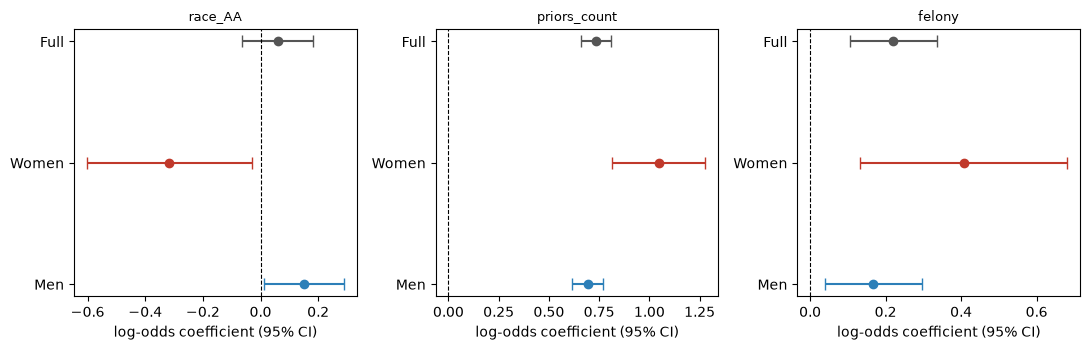

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, f in zip(axes, ["race_AA", "priors_count", "felony"]):
    for i, (r, col) in enumerate(zip(fits.values(), ["#555", "#c0392b", "#2c7fb8"])):
        lo, hi = r.conf_int().loc[f]
        ax.errorbar(r.params[f], i, xerr=[[r.params[f] - lo], [hi - r.params[f]]], fmt="o", color=col, capsize=4)
    ax.axvline(0, c="k", lw=.8, ls="--"); ax.set_yticks([0, 1, 2]); ax.set_yticklabels(["Full", "Women", "Men"]); ax.invert_yaxis()
    ax.set_title(f, fontsize=9); ax.set_xlabel("log-odds coefficient (95% CI)")
plt.tight_layout(); save_fig("part21_forest_by_sex"); plt.show()

2.2: dropped priors_counts

In [13]:
FEATS_RED = [f for f in FEATS if f != "priors_count"]
res_red = logit(X[FEATS_RED], y)
b0, b1 = res_full.params[FEATS_RED], res_red.params[FEATS_RED]
omv = pd.DataFrame({"full": b0, "full p": res_full.pvalues[FEATS_RED], "reduced": b1, "reduced p": res_red.pvalues[FEATS_RED],
                    "abs change": b1 - b0, "% change": 100 * (b1 - b0) / b0.abs()})
omv = omv.sort_values("% change", key=abs, ascending=False)
print("largest % change:", omv["% change"].abs().idxmax(), "| largest absolute change:", omv["abs change"].abs().idxmax())
print(f"race_AA odds ratio: {np.exp(b0['race_AA']):.2f} -> {np.exp(b1['race_AA']):.2f}")
print(f"corr(priors_count, race_AA) = {X['priors_count'].corr(X['race_AA']):.3f}")

# predictive cost of dropping priors: same models fitted on train, scored on test
auc_full = roc_auc_score(yte, pB)
auc_red = roc_auc_score(yte, logit(Xtr[FEATS_RED], ytr).predict(sm.add_constant(Xte[FEATS_RED])))
print(f"test AUC: full {auc_full:.3f} -> reduced {auc_red:.3f}")
omv.round(4)

largest % change: juv_fel_count | largest absolute change: race_AA
race_AA odds ratio: 1.06 -> 1.36
corr(priors_count, race_AA) = 0.221
test AUC: full 0.721 -> reduced 0.650


,full,full p,reduced,reduced p,abs change,% change
juv_fel_count,0.0065,0.8366,0.1261,0.0000,0.1196,"1,830.9655"
juv_misd_count,0.0183,0.5808,0.1640,0.0000,0.1457,796.5187
race_AA,0.0594,0.3484,0.3064,0.0000,0.2470,415.5717
felony,0.2203,0.0002,0.3791,0.0000,0.1588,72.1154
age,-0.4977,0.0000,-0.3014,0.0000,0.1963,39.4459
juv_other_count,0.1216,0.0001,0.1677,0.0000,0.0461,37.8796
male,0.3291,0.0000,0.4441,0.0000,0.1150,34.9454
race_Other,-0.1876,0.1250,-0.2351,0.0478,-0.0475,-25.2979
race_Hisp,-0.1752,0.1098,-0.1698,0.1073,0.0054,3.0674


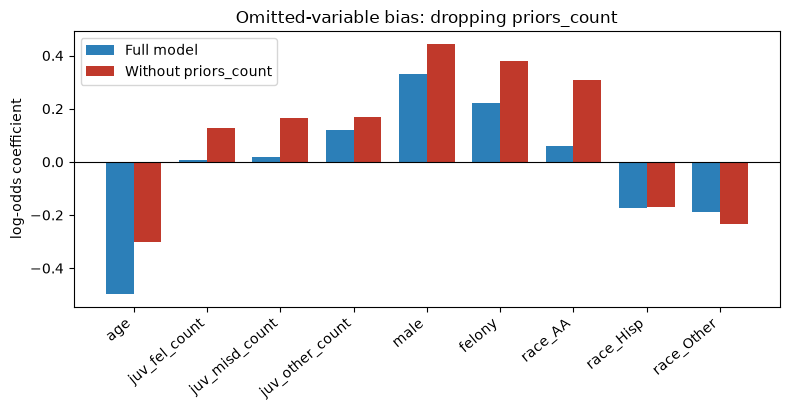

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.2))
idx, w = np.arange(len(FEATS_RED)), .38
ax.bar(idx - w/2, b0, w, label="Full model", color="#2c7fb8")
ax.bar(idx + w/2, b1, w, label="Without priors_count", color="#c0392b")
ax.set_xticks(idx); ax.set_xticklabels(FEATS_RED, rotation=40, ha="right"); ax.axhline(0, c="k", lw=.8)
ax.set_ylabel("log-odds coefficient"); ax.set_title("Omitted-variable bias: dropping priors_count"); ax.legend()
plt.tight_layout(); save_fig("part22_before_after"); plt.show()

2.3

In [15]:
te = d.loc[te_idx].copy()
te["p"], te["y"] = pB.values, yte.values
conf_fp = (te["p"] >= .75) & (te["y"] == 0)
conf_fn = (te["p"] <= .25) & (te["y"] == 1)
wrong = conf_fp | conf_fn
print(f"confident wrong: {wrong.sum()} = {100*wrong.mean():.2f}% of the test set")
print(f"  P >= 0.75: {(te['p'] >= .75).sum()}, of which wrong {conf_fp.sum()}")
print(f"  P <= 0.25: {(te['p'] <= .25).sum()}, of which wrong {conf_fn.sum()} ({100*conf_fn.sum()/(te['p'] <= .25).sum():.1f}%)")
sub50 = te[wrong].sample(50, random_state=SEED)

confident wrong: 93 = 5.02% of the test set
  P >= 0.75: 167, of which wrong 30
  P <= 0.25: 304, of which wrong 63 (20.7%)


In [16]:
def profile(df):
    return pd.Series({"n": len(df), "mean age": df["age"].mean(), "% age <25": 100 * (df["age"] < 25).mean(),
                      "% age >45": 100 * (df["age"] > 45).mean(), "% male": 100 * df["male"].mean(),
                      "% African-American": 100 * df["race_AA"].mean(), "% Caucasian": 100 * (df["race_grp"] == "Caucasian").mean(),
                      "% Hispanic": 100 * df["race_Hisp"].mean(), "mean priors": df["priors_count"].mean(),
                      "median priors": df["priors_count"].median(), "% felony": 100 * df["felony"].mean(),
                      "actual recid %": 100 * df["y"].mean()})
pd.DataFrame({"subset (50)": profile(sub50), "test set": profile(te)}).round(2)

,subset (50),test set
n,50.0000,"1,852.0000"
mean age,44.0200,34.8300
% age <25,4.0000,21.9800
% age >45,46.0000,19.9800
% male,80.0000,80.0800
% African-American,34.0000,50.5900
% Caucasian,46.0000,34.2300
% Hispanic,16.0000,8.9100
mean priors,5.6000,3.2700
median priors,2.0000,1.0000


**Common characteristic** and the two clusters inside the subset.

In [17]:
rules = {"priors_count >= 10": "priors_count >= 10", "age > 45": "age > 45", "priors_count <= 1": "priors_count <= 1",
         "age > 45 OR priors_count >= 10": "(age > 45) | (priors_count >= 10)"}
print(pd.DataFrame({"% of subset": {k: 100 * sub50.eval(v).mean() for k, v in rules.items()},
                    "% of test set": {k: 100 * te.eval(v).mean() for k, v in rules.items()}}).round(1), "\n")
for name, s in [("confident false positives", sub50[sub50["p"] >= .75]), ("confident false negatives", sub50[sub50["p"] <= .25])]:
    print(f"{name}: n={len(s)} ({100*len(s)/50:.0f}%), mean age {s['age'].mean():.1f}, median priors {s['priors_count'].median():.0f}, "
          f"% male {100*s['male'].mean():.0f}, % African-American {100*s['race_AA'].mean():.0f}")

                                % of subset  % of test set
priors_count >= 10                  32.0000         9.4000
age > 45                            46.0000        20.0000
priors_count <= 1                   48.0000        51.5000
age > 45 OR priors_count >= 10      74.0000        27.5000 

confident false positives: n=18 (36%), mean age 34.6, median priors 14, % male 100, % African-American 78
confident false negatives: n=32 (64%), mean age 49.3, median priors 1, % male 69, % African-American 9


**Why it fails:** the model assumes log-odds are linear in priors. Predicted vs observed recidivism by priors bin:

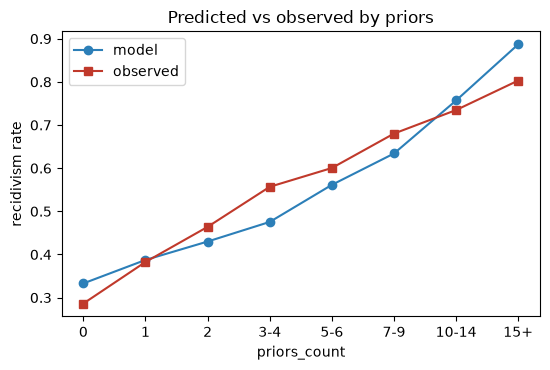

,n,predicted,observed
priors_bin,,,
0,2085,0.3330,0.2860
1,1129,0.3870,0.3830
2,681,0.4300,0.4640
3-4,783,0.4750,0.5570
5-6,468,0.5610,0.6000
7-9,444,0.6340,0.6800
10-14,328,0.7570,0.7350
15+,254,0.8870,0.8030


In [18]:
dd = d.assign(p=logB.predict(sm.add_constant(X[FEATS])))
dd["priors_bin"] = pd.cut(dd["priors_count"], [-1, 0, 1, 2, 4, 6, 9, 14, 100],
                          labels=["0", "1", "2", "3-4", "5-6", "7-9", "10-14", "15+"])
nl = dd.groupby("priors_bin", observed=True).agg(n=("is_recidivist", "size"), predicted=("p", "mean"), observed=("is_recidivist", "mean"))

fig, ax = plt.subplots(figsize=(5.6, 3.8))
ax.plot(nl.index.astype(str), nl["predicted"], "o-", label="model", c="#2c7fb8")
ax.plot(nl.index.astype(str), nl["observed"], "s-", label="observed", c="#c0392b")
ax.set_xlabel("priors_count"); ax.set_ylabel("recidivism rate"); ax.legend(); ax.set_title("Predicted vs observed by priors")
plt.tight_layout(); save_fig("part23_priors_nonlinearity"); plt.show()
nl.round(3)

2.4

In [19]:
thresholds = np.round(np.arange(0.05, 0.96, 0.10), 2)
yv, pv = te["y"].values, te["p"].values
mA, mB = (te["race_grp"] == "Caucasian").values, (te["race_grp"] == "African-American").values
print(f"test sizes: A = {mA.sum()}, B = {mB.sum()} | base rates: A = {yv[mA].mean():.3f}, B = {yv[mB].mean():.3f}")

rows = []
for t in thresholds:
    yh = (pv >= t).astype(int)
    a, b = rates(yv[mA], yh[mA]), rates(yv[mB], yh[mB])
    rows.append({"t": t, "DP": a["sel"] / b["sel"], "EO": min(a["TPR"] / b["TPR"], a["FPR"] / b["FPR"]),
                 "PP": a["PPV"] / b["PPV"], "accuracy": (yh == yv).mean(),
                 **{f"{k} A": v for k, v in a.items()}, **{f"{k} B": v for k, v in b.items()}})
fair = pd.DataFrame(rows).set_index("t")
fair.round(3)

test sizes: A = 634, B = 937 | base rates: A = 0.379, B = 0.524


,DP,EO,PP,accuracy,sel A,TPR A,FPR A,PPV A,sel B,TPR B,FPR B,PPV B
t,,,,,,,,,,,,
0.0500,1.0000,1.0000,0.7220,0.4500,1.0000,1.0000,1.0000,0.3790,1.0000,1.0000,1.0000,0.5240
0.1500,0.9480,0.9320,0.7480,0.4810,0.9370,0.9790,0.9110,0.3960,0.9880,0.9980,0.9780,0.5290
0.2500,0.8240,0.8060,0.7750,0.5460,0.7630,0.8620,0.7030,0.4280,0.9260,0.9760,0.8720,0.5520
0.3500,0.6870,0.6670,0.8170,0.6210,0.5570,0.7120,0.4620,0.4840,0.8100,0.9160,0.6930,0.5930
0.4500,0.5240,0.5550,0.8040,0.6610,0.3260,0.4580,0.2460,0.5310,0.6230,0.7860,0.4440,0.6610
0.5500,0.4190,0.4550,0.8470,0.6640,0.1700,0.2790,0.1040,0.6200,0.4070,0.5680,0.2290,0.7320
0.6500,0.3510,0.3480,0.9180,0.6410,0.0900,0.1710,0.0410,0.7190,0.2560,0.3830,0.1170,0.7830
0.7500,0.1680,0.1730,0.7470,0.6080,0.0250,0.0420,0.0150,0.6250,0.1500,0.2400,0.0520,0.8370
0.8500,0.2170,0.2520,0.8390,0.5850,0.0170,0.0330,0.0080,0.7270,0.0800,0.1320,0.0220,0.8670


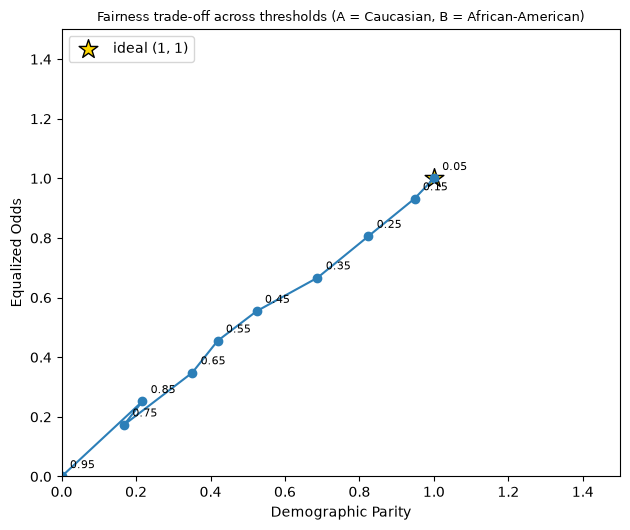

In [20]:
fig, ax = plt.subplots(figsize=(6.4, 5.4))
ax.plot(fair["DP"], fair["EO"], "o-", c="#2c7fb8")
for t, r in fair.iterrows():
    ax.annotate(f"{t:.2f}", (r["DP"], r["EO"]), textcoords="offset points", xytext=(6, 6), fontsize=8)
ax.scatter([1], [1], marker="*", s=200, c="gold", edgecolor="k", label="ideal (1, 1)")
ax.set_xlim(0, 1.5); ax.set_ylim(0, 1.5); ax.legend(loc="upper left")
ax.set_xlabel("Demographic Parity"); ax.set_ylabel("Equalized Odds")
ax.set_title("Fairness trade-off across thresholds (A = Caucasian, B = African-American)", fontsize=9)
plt.tight_layout(); save_fig("part24_tradeoff_DP_vs_EO"); plt.show()

**Threshold trade-off**

In [21]:
f, t = fair.loc[0.65], fair.loc[0.35]
chg = lambda m: 100 * (t[m] - f[m]) / f[m]
print(f"DP improves {f['DP']:.3f} -> {t['DP']:.3f} ({chg('DP'):+.1f}%)")
print(f"EO          {f['EO']:.3f} -> {t['EO']:.3f} ({chg('EO'):+.1f}%)")
print(f"PP drops    {f['PP']:.3f} -> {t['PP']:.3f} ({chg('PP'):+.1f}%)")
print(f"trade-off cost (PP lost per 1% DP gained) = {-chg('PP') / chg('DP'):.3f}")
print(f"correlation of DP and EO across thresholds: {fair['DP'].corr(fair['EO']):.3f}")

DP improves 0.351 -> 0.687 (+95.8%)
EO          0.348 -> 0.667 (+91.4%)
PP drops    0.918 -> 0.817 (-11.0%)
trade-off cost (PP lost per 1% DP gained) = 0.115
correlation of DP and EO across thresholds: 0.998


In [22]:
cand_A = te[(te["race_grp"] == "Caucasian") & (te["y"] == 1)]
cand_B = te[(te["race_grp"] == "African-American") & (te["y"] == 0)]
iA, iB = (cand_A["p"] - 0.40).abs().idxmin(), (cand_B["p"] - 0.55).abs().idxmin()
pair = te.loc[[iA, iB], ["race_grp", "sex", "age", "priors_count", "c_charge_degree", "p", "y"]]
pair.index = ["Person 1", "Person 2"]
for t in thresholds:
    pair[f"flagged@{t:.2f}"] = (pair["p"] >= t).astype(int)
pair.T

,Person 1,Person 2
race_grp,Caucasian,African-American
sex,Male,Male
age,35,40
priors_count,3,6
c_charge_degree,M,F
p,0.4001,0.5480
y,1,0
flagged@0.05,1,1
flagged@0.15,1,1
flagged@0.25,1,1


In [23]:
young_c = mA & (te["age"].values < 25)
for t in [0.55, 0.65, 0.75]:
    print(f"t = {t}: {(pv[young_c] >= t).sum()} of {young_c.sum()} flagged")

t = 0.55: 37 of 97 flagged
t = 0.65: 21 of 97 flagged
t = 0.75: 4 of 97 flagged


In [24]:
def two_thresholds(tA, tB):
    yh = np.where(mB, pv >= tB, pv >= tA).astype(int)
    a, b = rates(yv[mA], yh[mA]), rates(yv[mB], yh[mB])
    AB = mA | mB
    return {"t A": tA, "t B": tB, "sel A": a["sel"], "sel B": b["sel"], "DP": a["sel"] / b["sel"],
            "FPR A": a["FPR"], "FPR B": b["FPR"], "FPR ratio": a["FPR"] / b["FPR"],
            "PP": a["PPV"] / b["PPV"], "accuracy": (yh[AB] == yv[AB]).mean()}

grid = np.round(np.arange(0.55, 0.95, 0.005), 3)
t_dp = min(grid, key=lambda tb: abs(two_thresholds(0.55, tb)["DP"] - 1))
t_eo = min(grid, key=lambda tb: abs(two_thresholds(0.55, tb)["FPR ratio"] - 1))
pd.DataFrame([two_thresholds(0.55, 0.55), two_thresholds(0.55, t_dp), two_thresholds(0.55, t_eo)],
             index=["single t = 0.55", "match DP", "match FPR (EO)"]).round(4)

,t A,t B,sel A,sel B,DP,FPR A,FPR B,FPR ratio,PP,accuracy
single t = 0.55,0.5500,0.5500,0.1703,0.4066,0.4189,0.1041,0.2287,0.4550,0.8472,0.6639
match DP,0.5500,0.7250,0.1703,0.1708,0.9976,0.1041,0.0695,1.4971,0.7695,0.6136
match FPR (EO),0.5500,0.6650,0.1703,0.2348,0.7255,0.1041,0.1054,0.9875,0.7889,0.6314


## References in Report
The answers from the pdf report are proved in the code via the following:

| Question | Section |
|---|---|
| Q1 | Model A-B Comparison |
| Q2 | 2.1 |
| Q3 | 2.2 |
| Q4 | N/A|
| Q5 | 2.3 |
| Q6 | 2.4 |
| Q7 | 2.4 |
| Q8 | 2.4 |